# Final test evaluation
Run after configuration is finalized. Uses best validation checkpoint.

In [1]:
from pathlib import Path
import sys
MODULE = Path(r"D:\HK261\DeepLearning\Assignment\Assignment\src\a3_image_only")
if not MODULE.is_dir(): MODULE = Path.cwd()
sys.path.insert(0, str(MODULE))
from config import Config
cfg = Config()
# cfg.split_dir = Path(r"...folder containing train.csv, validation.csv, test.csv, labels.json...")
print(cfg.splits())


D:\HK261\DeepLearning\Assignment\Assignment\data\processed\abo


In [2]:
from evaluate import evaluate
scores,pred=evaluate(cfg)
display(scores)


d:\Systems\Anaconda\envs\btvn6_7\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'loss': 0.37590004157481727, 'accuracy': 0.8936970837253058, 'macro_f1': 0.9061128227301559, 'seconds': 7.316683600016404, 'ms_per_sample': 6.883051364079401, 'checkpoint_epoch': 11, 'parameters': 23532620, 'training_seconds': 749.0398281000671, 'through_best_only': False, 'forward_ms_per_image': 0.9071565624253708, 'latency_batch_size': 32}


{'loss': 0.37590004157481727,
 'accuracy': 0.8936970837253058,
 'macro_f1': 0.9061128227301559,
 'seconds': 7.316683600016404,
 'ms_per_sample': 6.883051364079401,
 'checkpoint_epoch': 11,
 'parameters': 23532620,
 'training_seconds': 749.0398281000671,
 'through_best_only': False,
 'forward_ms_per_image': 0.9071565624253708,
 'latency_batch_size': 32}

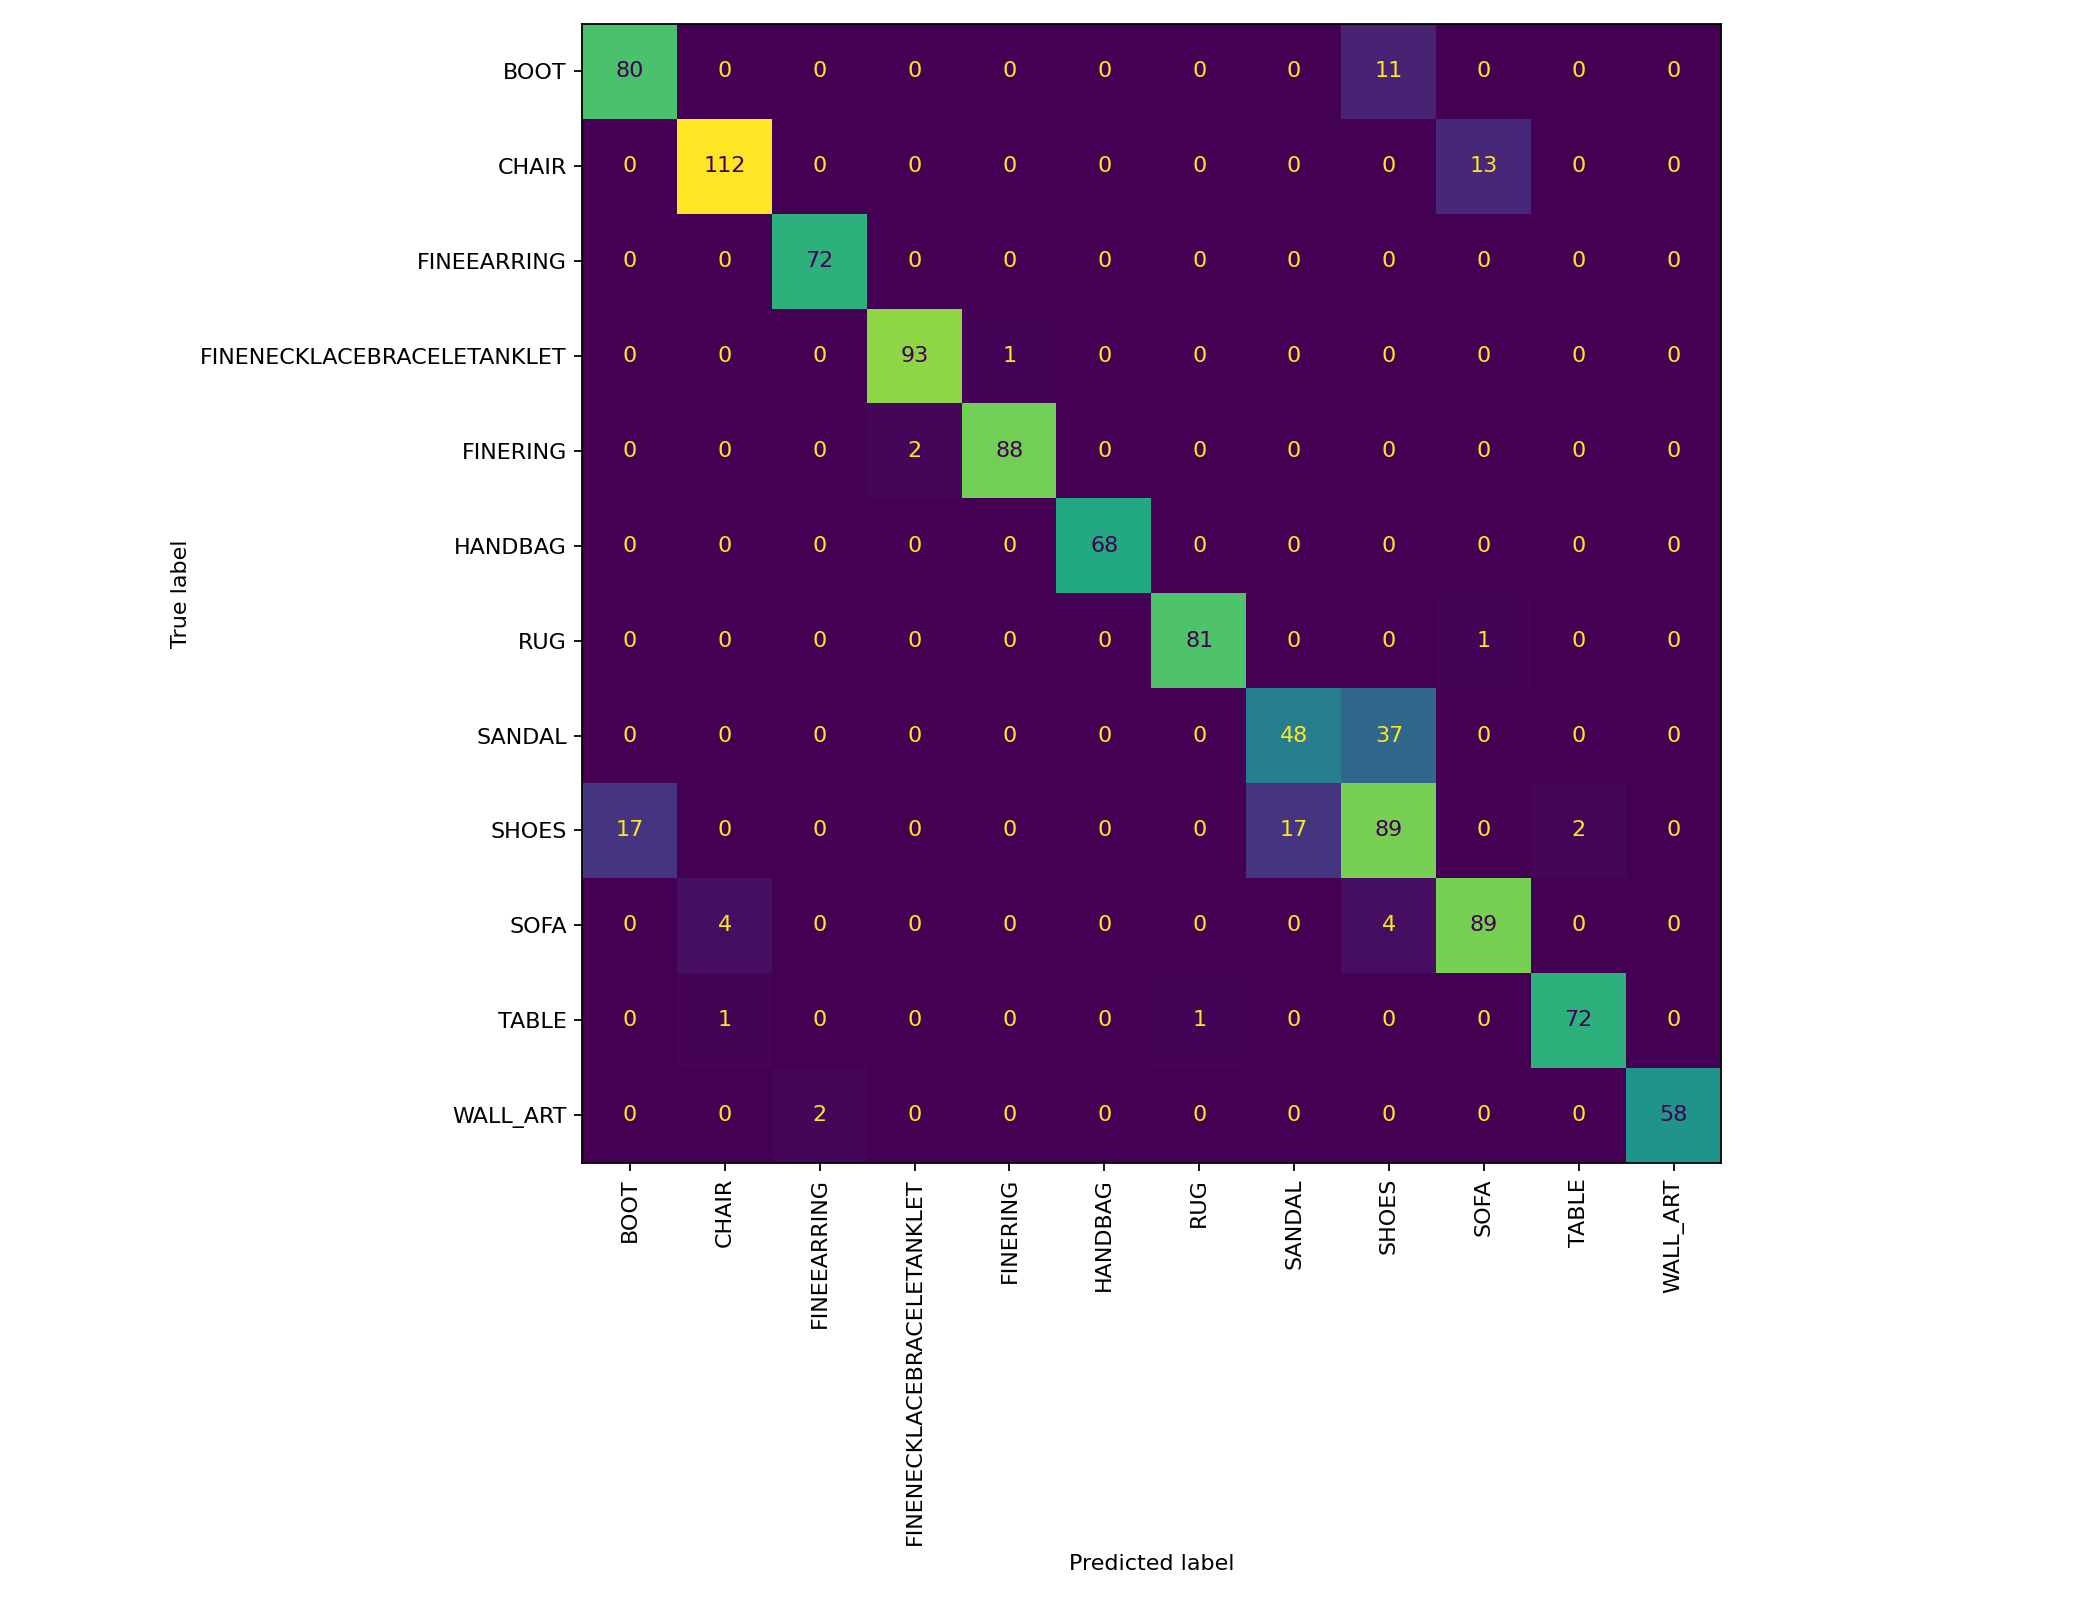

In [3]:
from IPython.display import Image as DisplayImage, display
display(DisplayImage(filename=str(cfg.output_dir/'confusion_matrix.png')))


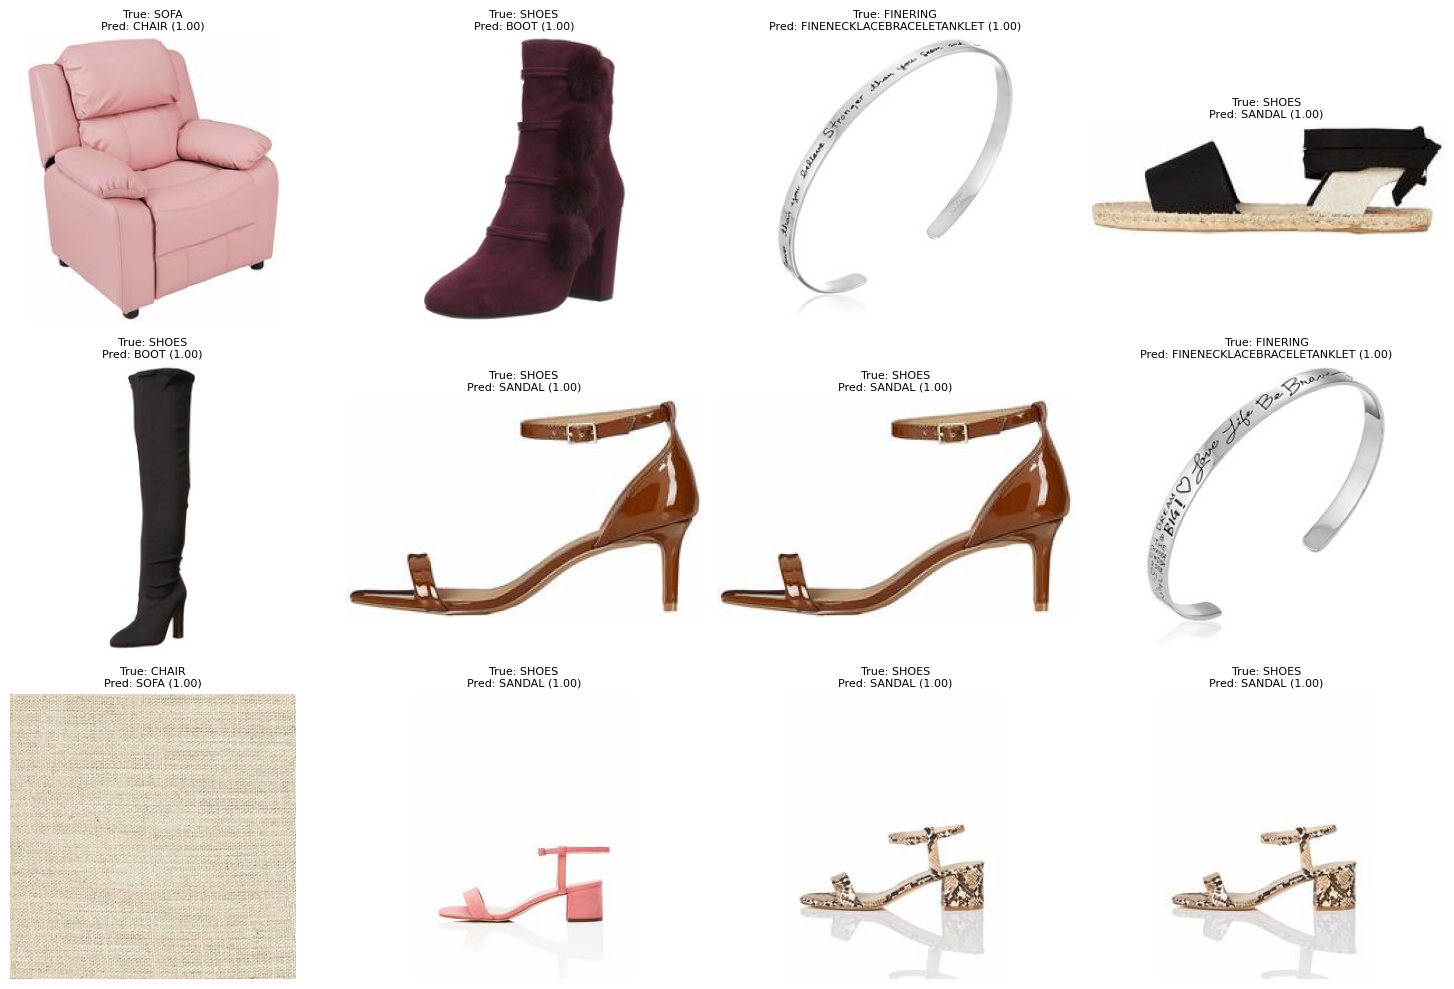

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
errors=pred.loc[~pred.correct].sort_values('confidence',ascending=False).head(12)
fig,axes=plt.subplots(3,4,figsize=(15,10))
for ax in axes.flat: ax.axis('off')
for ax,(_,r) in zip(axes.flat,errors.iterrows()):
    with Image.open(r.local_path) as im: ax.imshow(im.convert('RGB'))
    ax.set_title(f'True: {r.product_type}\nPred: {r.predicted_type} ({r.confidence:.2f})',fontsize=8)
plt.tight_layout()
